# LoRA Fine-Tuning: A Comparative Study of Accuracy, Parameter Efficiency, and Computational Cost

### Experimental Analysis of Low-Rank Adaptation (LoRA) and Full Fine-Tuning Using DistilBERT on the IMDb Sentiment Classification Dataset

**Objective:** To investigate how different LoRA ranks (4, 8, and 16) affect model performance, trainable parameters, training time, and GPU memory consumption compared with full fine-tuning.

**Research Focus:**
- Understand and implement Low-Rank Adaptation (LoRA).
- Compare LoRA with conventional full fine-tuning.
- Evaluate the effect of different LoRA ranks on classification performance.
- Analyse parameter efficiency and computational requirements.
- Identify the trade-off between model accuracy and training efficiency.

**Model:** DistilBERT (distilbert-base-uncased)  
**Dataset:** IMDb Movie Reviews  
**Task:** Binary Sentiment Classification  
**Framework:** PyTorch, Hugging Face Transformers and PEFT

## 1. Install dependencies

This cell prepares the notebook environment before importing the machine-learning libraries.

- It removes `torchao`, which can cause a version-compatibility error with some installed versions of PEFT.
- It installs or updates `peft` (for LoRA adapters) and `datasets` (for loading IMDb from Hugging Face).
- If the notebook environment asks for a restart after installation, restart the runtime and continue from the imports section.

Run this cell once at the beginning of a fresh Colab session. It does not train a model.

In [1]:
!pip uninstall -y -q torchao
!pip install -q peft datasets

## 2. Imports and experiment configuration

This section imports the libraries used for data handling, model training, evaluation, and plotting. It also defines the settings shared by the experiments.

Important settings:
- **Model:** DistilBERT base uncased.
- **Maximum sequence length:** 128 tokens; longer reviews are truncated and shorter ones are padded.
- **Batch size:** 16; **epochs:** 3 in the full experiment.
- **LoRA ranks:** 4, 8, and 16.
- **Target modules:** the query and value projection layers (`q_lin` and `v_lin`).
- **Seeds:** 0, 1, and 2 for the final repeated experiments.
- **QUICK_MODE:** when enabled, runs a small smoke test. Its results must not be used as the final research results.

The fixed data seed keeps the selected dataset examples consistent, while the run seeds vary model initialisation, dropout, and data order. The device check selects a GPU when one is available.

In [2]:
import os, time, random, json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from peft import LoraConfig, get_peft_model, TaskType
from torch.utils.data import TensorDataset, DataLoader
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score

QUICK_MODE = False          # True = tiny smoke test, NOT for reporting

DATA_SEED   = 42            # fixes the train/val/test subsets for every run
MODEL_NAME  = "distilbert/distilbert-base-uncased"
MAX_LENGTH  = 128
BATCH_SIZE  = 16
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06

if QUICK_MODE:
    N_TRAIN, N_VAL, N_TEST, EPOCHS = 1000, 400, 400, 1
    SEEDS = [0]
    LR_GRID = {"Full": [5e-5], "LoRA": [3e-4]}
else:
    N_TRAIN, N_VAL, N_TEST, EPOCHS = 5000, 1000, 2000, 3
    SEEDS = [0, 1, 2]
    LR_GRID = {"Full": [2e-5, 5e-5], "LoRA": [1e-4, 3e-4, 1e-3]}

RANKS = [4, 8, 16]
LORA_ALPHA_FACTOR = 2       # alpha = 2 * rank (constant scaling alpha/r = 2)
LORA_DROPOUT = 0.1
TARGET_MODULES = ["q_lin", "v_lin"]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected: memory numbers will be NaN and training will be slow.")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

os.makedirs("results", exist_ok=True)

Device: cuda
GPU: Tesla T4


## 3. Load and prepare the IMDb dataset

This cell downloads the IMDb movie-review sentiment dataset and divides it into three non-overlapping subsets.

- **Training set:** 5,000 reviews used to update model parameters.
- **Validation set:** 1,000 reviews taken from the original training split and used for learning-rate selection and LoRA-rank selection.
- **Test set:** 2,000 reviews taken from the official IMDb test split and reserved for final evaluation.

The tokenizer converts each review into token IDs and attention masks. Reviews are padded or truncated to 128 tokens, then stored as PyTorch tensors so they can be loaded in batches.

The printed positive-label fraction is a quick check of the label distribution in each subset. The test set is not used to choose hyperparameters.

In [3]:
raw = load_dataset("stanfordnlp/imdb")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_all = raw["train"].shuffle(seed=DATA_SEED)
train_raw = train_all.select(range(N_TRAIN))
val_raw   = train_all.select(range(N_TRAIN, N_TRAIN + N_VAL))
test_raw  = raw["test"].shuffle(seed=DATA_SEED).select(range(N_TEST))

def to_tensor_ds(split):
    enc = tokenizer([str(t) for t in split["text"]], truncation=True,
                    padding="max_length", max_length=MAX_LENGTH, return_tensors="pt")
    return TensorDataset(enc["input_ids"], enc["attention_mask"],
                         torch.tensor(split["label"], dtype=torch.long))

train_ds, val_ds, test_ds = map(to_tensor_ds, (train_raw, val_raw, test_raw))
val_loader  = DataLoader(val_ds,  batch_size=64, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    pos = ds.tensors[2].float().mean().item()
    print(f"{name:5s}: {len(ds):5d} examples | positive fraction = {pos:.3f}")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

... (5 outputs left out)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

train:  5000 examples | positive fraction = 0.501
val  :  1000 examples | positive fraction = 0.518
test :  2000 examples | positive fraction = 0.500


## 4. Define the model, parameter counting, training, and evaluation utilities

This cell defines reusable functions so that full fine-tuning and every LoRA configuration are trained and evaluated using the same procedure.

1. `build_model()` loads DistilBERT for binary sentiment classification and, for LoRA runs, inserts low-rank adapters into the query and value projection layers.
2. `param_breakdown()` counts trainable parameters and separates the LoRA adapter weights from the classification head. This distinction matters because the classification head is also trainable during LoRA fine-tuning.
3. `evaluate()` calculates accuracy and weighted F1 on a supplied data loader.
4. `run_experiment()` trains one configuration, measures training time and peak allocated GPU memory, and records validation metrics. It evaluates the test set only when `with_test=True`.
5. `gpu_warmup()` performs a short preliminary GPU run so that one-time GPU initialisation overhead is less likely to distort the measured training time.

The reported parameter percentages use the original DistilBERT classifier's parameter count as the denominator. Training time covers the training loop, while peak memory is measured during training.

In [4]:
def build_model(method, rank=None):
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    base_total = sum(p.numel() for p in model.parameters())
    if method == "LoRA":
        cfg = LoraConfig(
            task_type=TaskType.SEQ_CLS,
            r=rank,
            lora_alpha=LORA_ALPHA_FACTOR * rank,
            lora_dropout=LORA_DROPOUT,
            target_modules=TARGET_MODULES,
            modules_to_save=["pre_classifier", "classifier"],
        )
        model = get_peft_model(model, cfg)
    return model, base_total

def param_breakdown(model, base_total):
    trainable = [(n, p.numel()) for n, p in model.named_parameters() if p.requires_grad]
    total_trainable = sum(c for _, c in trainable)
    adapter = sum(c for n, c in trainable if "lora_" in n)
    head = sum(c for n, c in trainable if "lora_" not in n and "classifier" in n)
    return {
        "trainable_params": total_trainable,
        "adapter_params": adapter,
        "head_params": head,
        "trainable_pct_of_base": 100 * total_trainable / base_total,
        "adapter_pct_of_base": 100 * adapter / base_total,
    }

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    y_true, y_pred = [], []
    for ids, mask, labels in loader:
        logits = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE)).logits
        y_pred.extend(logits.argmax(dim=1).cpu().tolist())
        y_true.extend(labels.tolist())
    return accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average="weighted")

def sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def run_experiment(method, rank, lr, seed, with_test=False):
    set_seed(seed)                       # before model creation: head/LoRA init depends on seed
    model, base_total = build_model(method, rank)
    model.to(DEVICE)
    counts = param_breakdown(model, base_total)

    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g)
    optimizer = AdamW([p for p in model.parameters() if p.requires_grad],
                      lr=lr, weight_decay=WEIGHT_DECAY)
    total_steps = EPOCHS * len(loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    sync(); start = time.time()
    model.train()
    last_loss = float("nan")
    for epoch in range(EPOCHS):
        running = 0.0
        for ids, mask, labels in loader:
            optimizer.zero_grad()
            out = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), labels=labels.to(DEVICE))
            out.loss.backward()
            optimizer.step(); scheduler.step()
            running += out.loss.item()
        last_loss = running / len(loader)
    sync(); train_seconds = time.time() - start
    peak_mb = torch.cuda.max_memory_allocated() / 2**20 if torch.cuda.is_available() else float("nan")

    val_acc, val_f1 = evaluate(model, val_loader)
    res = {
        "method": method, "rank": rank if rank is not None else 0, "lr": lr, "seed": seed,
        "config": "Full FT" if method == "Full" else f"LoRA r={rank}",
        "final_train_loss": last_loss, "val_acc": val_acc, "val_f1": val_f1,
        "train_seconds": train_seconds, "peak_gpu_mb": peak_mb, **counts,
    }
    if with_test:                         # test is evaluated only for final runs, never used for selection
        res["test_acc"], res["test_f1"] = evaluate(model, test_loader)

    del model, optimizer, scheduler
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return res

def gpu_warmup(n_steps=10):
    # Absorbs one-time CUDA/cuDNN initialisation cost so it is not charged to the first timed run.
    set_seed(0)
    model, _ = build_model("Full"); model.to(DEVICE); model.train()
    opt = AdamW(model.parameters(), lr=1e-5)
    for i, (ids, mask, labels) in enumerate(DataLoader(train_ds, batch_size=BATCH_SIZE)):
        if i >= n_steps: break
        loss = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), labels=labels.to(DEVICE)).loss
        loss.backward(); opt.step(); opt.zero_grad()
    sync(); del model, opt
    if torch.cuda.is_available(): torch.cuda.empty_cache()

gpu_warmup()
print("Warm-up done.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Warm-up done.


## 5. Select learning rates using validation accuracy

Full fine-tuning and LoRA can require different learning rates, so this experiment does not force every method to use one shared learning rate.

For each configuration (full fine-tuning and LoRA ranks 4, 8, and 16), the notebook trains a short learning-rate sweep using the values defined in the configuration cell. Every trial uses seed 0 and is evaluated on the validation set.

The learning rate with the highest validation accuracy is selected separately for each configuration. The sweep results are saved to `results/lr_sweep.csv`.

**Important:** the test set is not evaluated during this selection stage. This helps keep the test set independent of hyperparameter selection.

In [5]:
configs = [("Full", None)] + [("LoRA", r) for r in RANKS]

sweep_rows = []
for method, rank in configs:
    for lr in LR_GRID[method]:
        r = run_experiment(method, rank, lr, seed=0, with_test=False)
        sweep_rows.append(r)
        print(f"{r['config']:10s} lr={lr:<8g} val_acc={r['val_acc']:.4f} train_loss={r['final_train_loss']:.4f}")

sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv("results/lr_sweep.csv", index=False)

best_lr = (sweep_df.sort_values("val_acc", ascending=False)
                   .groupby("config", sort=False).head(1)
                   .set_index("config")["lr"].to_dict())
print("\nSelected learning rates:", best_lr)
sweep_df[["config", "lr", "val_acc", "final_train_loss"]]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Full FT    lr=2e-05    val_acc=0.8590 train_loss=0.1525


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Full FT    lr=5e-05    val_acc=0.8460 train_loss=0.0740


... (24 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


LoRA r=16  lr=0.001    val_acc=0.8550 train_loss=0.2193

Selected learning rates: {'Full FT': 2e-05, 'LoRA r=16': 0.001, 'LoRA r=4': 0.001, 'LoRA r=8': 0.001}


,config,lr,val_acc,final_train_loss
0,Full FT,0.00002,0.859,0.152514
1,Full FT,0.00005,0.846,0.074005
2,LoRA r=4,0.00010,0.823,0.365515
3,LoRA r=4,0.00030,0.837,0.320636
4,LoRA r=4,0.00100,0.845,0.265365
5,LoRA r=8,0.00010,0.822,0.353157
6,LoRA r=8,0.00030,0.837,0.308457
7,LoRA r=8,0.00100,0.842,0.243178
8,LoRA r=16,0.00010,0.830,0.338207
9,LoRA r=16,0.00030,0.836,0.289025


## 6. Run the final experiments with three random seeds

After selecting a learning rate for each configuration, this cell performs the final repeated experiments using seeds 0, 1, and 2.

For each seed, it trains:
- one full fine-tuning model;
- one LoRA model with rank 4;
- one LoRA model with rank 8;
- one LoRA model with rank 16.

Each run records validation accuracy, test accuracy, training time, peak GPU memory, and parameter counts. The test set is evaluated here for final reporting; its scores are not used to select the learning rate or rank.

The individual run results are collected in a DataFrame and saved to `results/final_runs.csv`. Repeating each configuration with three seeds gives an indication of how much the measurements vary with random initialisation and training order.

In [6]:
final_rows = []
for method, rank in configs:
    cfg_name = "Full FT" if method == "Full" else f"LoRA r={rank}"
    for seed in SEEDS:
        r = run_experiment(method, rank, best_lr[cfg_name], seed=seed, with_test=True)
        final_rows.append(r)
        print(f"{cfg_name:10s} seed={seed} lr={r['lr']:<8g} val={r['val_acc']:.4f} test={r['test_acc']:.4f} "
              f"time={r['train_seconds']:.1f}s mem={r['peak_gpu_mb']:.0f}MB")

final_df = pd.DataFrame(final_rows)
final_df.to_csv("results/final_runs.csv", index=False)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Full FT    seed=0 lr=2e-05    val=0.8590 test=0.8550 time=189.6s mem=1436MB


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Full FT    seed=1 lr=2e-05    val=0.8510 test=0.8515 time=189.6s mem=1436MB


... (26 outputs left out)

LoRA r=16  seed=1 lr=0.001    val=0.8520 test=0.8575 time=129.9s mem=804MB


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


LoRA r=16  seed=2 lr=0.001    val=0.8570 test=0.8475 time=130.1s mem=804MB


## 7. Aggregate results across random seeds

This cell groups the final runs by configuration and calculates the mean and standard deviation of the main metrics.

- **Mean:** the average result across the three seeds.
- **Standard deviation:** the variation between those three runs.
- **Accuracy and weighted F1:** summarise classification performance.
- **Training time and peak GPU memory:** describe the measured computational cost.
- **Parameter counts:** show the total trainable parameters and, separately, the adapter and classification-head parameters.

The LoRA rank with the highest **mean validation accuracy** is selected among ranks 4, 8, and 16. The test metrics are reported for comparison only and are not used to select the rank.

The aggregated table is saved to `results/summary.csv`. The displayed binomial standard-error estimate is a rough indication of sampling uncertainty for one test accuracy; it is not a confidence interval for the difference between methods.

In [7]:
order = ["Full FT"] + [f"LoRA r={r}" for r in RANKS]
g = final_df.groupby("config")
summary = pd.DataFrame({
    "lr": g["lr"].first(),
    "val_acc_mean": g["val_acc"].mean(),  "val_acc_std": g["val_acc"].std(ddof=1),
    "test_acc_mean": g["test_acc"].mean(), "test_acc_std": g["test_acc"].std(ddof=1),
    "test_f1_mean": g["test_f1"].mean(),
    "train_s_mean": g["train_seconds"].mean(), "train_s_std": g["train_seconds"].std(ddof=1),
    "peak_mb_mean": g["peak_gpu_mb"].mean(),
    "trainable_params": g["trainable_params"].first(),
    "adapter_params": g["adapter_params"].first(),
    "head_params": g["head_params"].first(),
    "trainable_pct_of_base": g["trainable_pct_of_base"].first(),
    "adapter_pct_of_base": g["adapter_pct_of_base"].first(),
}).loc[order]
summary.to_csv("results/summary.csv")

lora_val = summary.loc[[f"LoRA r={r}" for r in RANKS], "val_acc_mean"]
selected = lora_val.idxmax()
print(f"Rank selected on VALIDATION accuracy: {selected}  (val acc = {lora_val.max():.4f})")
print(f"Seeds per configuration: {len(SEEDS)} | test set size: {N_TEST} "
      f"| binomial s.e. of one test accuracy at 85%: ~{100*np.sqrt(0.85*0.15/N_TEST):.1f} pts")

disp = summary.copy()
for c in ["val_acc_mean", "val_acc_std", "test_acc_mean", "test_acc_std", "test_f1_mean"]:
    disp[c] = disp[c].map(lambda x: f"{x:.4f}")
disp

Rank selected on VALIDATION accuracy: LoRA r=16  (val acc = 0.8547)
Seeds per configuration: 3 | test set size: 2000 | binomial s.e. of one test accuracy at 85%: ~0.8 pts


,lr,val_acc_mean,val_acc_std,test_acc_mean,test_acc_std,test_f1_mean,train_s_mean,train_s_std,peak_mb_mean,trainable_params,adapter_params,head_params,trainable_pct_of_base,adapter_pct_of_base
config,,,,,,,,,,,,,,
Full FT,0.00002,0.8520,0.0066,0.8542,0.0024,0.8541,189.608028,0.057529,1435.895508,66955010,0,592130,100.000000,0.000000
LoRA r=4,0.00100,0.8477,0.0025,0.8458,0.0038,0.8457,129.238584,0.047225,799.864258,665858,73728,592130,0.994486,0.110116
LoRA r=8,0.00100,0.8490,0.0070,0.8445,0.0062,0.8444,129.258132,0.224827,801.083008,739586,147456,592130,1.104601,0.220231
LoRA r=16,0.00100,0.8547,0.0025,0.8507,0.0059,0.8506,129.998187,0.136588,803.520508,887042,294912,592130,1.324833,0.440463


## 8. Visualise performance and computational efficiency

The plots make it easier to compare the methods and understand the effect of LoRA rank.

1. **Test accuracy vs. rank:** compares the mean test accuracy for LoRA ranks 4, 8, and 16. Error bars show the standard deviation across the three seeds. The dashed line shows the full fine-tuning mean.
2. **Adapter parameters vs. rank:** shows how the number of LoRA adapter parameters grows as rank increases. The classification head is excluded from this plot so the adapter cost is visible separately.
3. **Training time:** compares average training-loop time across full fine-tuning and the LoRA configurations. Error bars show variation across seeds.
4. **Peak GPU memory:** compares the average peak allocated GPU memory during training. This plot is skipped automatically when the notebook runs without a CUDA GPU.

Each plot is displayed and saved as a PNG file in the `results` directory.

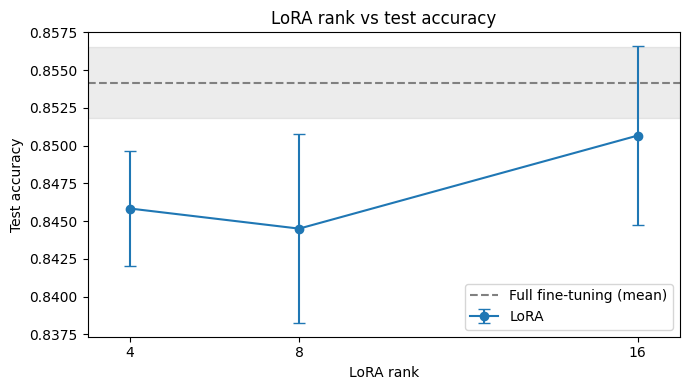

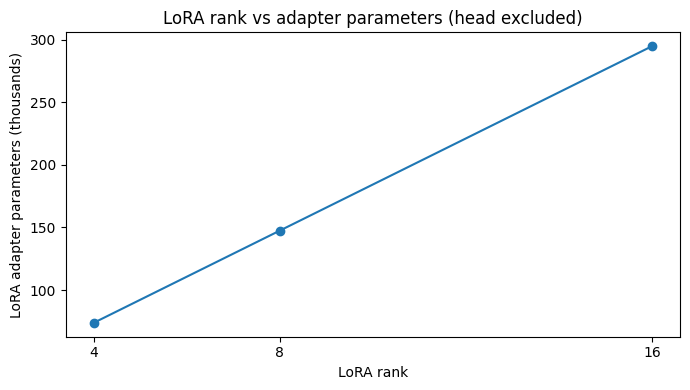

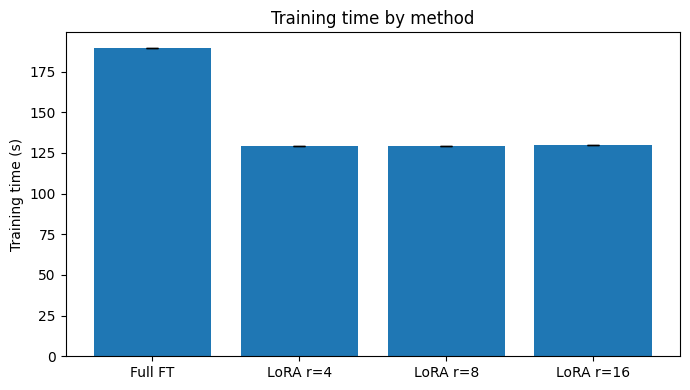

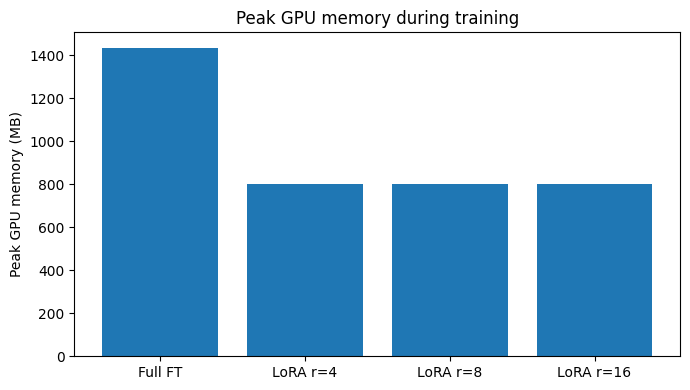

In [8]:
lora_cfgs = [f"LoRA r={r}" for r in RANKS]
full = summary.loc["Full FT"]

# Test accuracy vs rank
plt.figure(figsize=(7, 4))
plt.errorbar(RANKS, summary.loc[lora_cfgs, "test_acc_mean"], yerr=summary.loc[lora_cfgs, "test_acc_std"],
             marker="o", capsize=4, label="LoRA")
plt.axhline(full["test_acc_mean"], linestyle="--", color="gray", label="Full fine-tuning (mean)")
plt.fill_between([min(RANKS) - 1, max(RANKS) + 1],
                 full["test_acc_mean"] - full["test_acc_std"], full["test_acc_mean"] + full["test_acc_std"],
                 color="gray", alpha=0.15)
plt.xticks(RANKS); plt.xlim(min(RANKS) - 1, max(RANKS) + 1)
plt.xlabel("LoRA rank"); plt.ylabel("Test accuracy"); plt.title("LoRA rank vs test accuracy")
plt.legend(); plt.tight_layout(); plt.savefig("results/rank_vs_accuracy.png", dpi=150); plt.show()

# Adapter parameters vs rank
plt.figure(figsize=(7, 4))
plt.plot(RANKS, summary.loc[lora_cfgs, "adapter_params"] / 1e3, marker="o")
plt.xticks(RANKS); plt.xlabel("LoRA rank"); plt.ylabel("LoRA adapter parameters (thousands)")
plt.title("LoRA rank vs adapter parameters (head excluded)")
plt.tight_layout(); plt.savefig("results/rank_vs_adapter_params.png", dpi=150); plt.show()

# Training time
labels = order
plt.figure(figsize=(7, 4))
plt.bar(labels, summary.loc[labels, "train_s_mean"], yerr=summary.loc[labels, "train_s_std"], capsize=4)
plt.ylabel("Training time (s)"); plt.title("Training time by method")
plt.tight_layout(); plt.savefig("results/training_time.png", dpi=150); plt.show()

# Peak memory
if summary["peak_mb_mean"].notna().any():
    plt.figure(figsize=(7, 4))
    plt.bar(labels, summary.loc[labels, "peak_mb_mean"])
    plt.ylabel("Peak GPU memory (MB)"); plt.title("Peak GPU memory during training")
    plt.tight_layout(); plt.savefig("results/peak_memory.png", dpi=150); plt.show()
else:
    print("Memory plot skipped: CPU run.")

## 9. Generate a concise numerical results summary

This cell converts the aggregated experiment table into a short text report.

It reports the experiment setup, mean test accuracy and standard deviation, trainable parameter counts, average training time, peak GPU memory, and the LoRA rank selected using validation accuracy. It also calculates the percentage reduction in peak GPU memory for the selected LoRA configuration relative to full fine-tuning.

The summary is saved to `results/summary.txt`. These are measured results from the executed notebook, not theoretical estimates. If the experiment is rerun with different hardware, data settings, or seeds, the values may change.

In [9]:
f = summary.loc["Full FT"]
lines = []
lines.append(f"Setup: DistilBERT-base-uncased, IMDb subset ({N_TRAIN} train / {N_VAL} val / {N_TEST} test), "
             f"{EPOCHS} epochs, batch {BATCH_SIZE}, {len(SEEDS)} seeds, LR tuned per method on validation.")
lines.append(f"Full FT: test acc {f['test_acc_mean']*100:.1f} ± {f['test_acc_std']*100:.1f}%, "
             f"{f['trainable_params']/1e6:.1f}M trainable params, {f['train_s_mean']:.0f}s, {f['peak_mb_mean']:.0f} MB peak.")
for r in RANKS:
    s = summary.loc[f"LoRA r={r}"]
    lines.append(f"LoRA r={r}: test acc {s['test_acc_mean']*100:.1f} ± {s['test_acc_std']*100:.1f}%, "
                 f"adapter params {s['adapter_params']/1e3:.0f}K ({s['adapter_pct_of_base']:.2f}% of base) + "
                 f"head {s['head_params']/1e3:.0f}K, {s['train_s_mean']:.0f}s, {s['peak_mb_mean']:.0f} MB peak, lr={s['lr']:g}.")
lines.append(f"Rank selected on validation: {selected}.")
if "peak_mb_mean" in f and f["peak_mb_mean"] == f["peak_mb_mean"]:
    sel = summary.loc[selected]
    lines.append(f"Selected LoRA used {100*(1 - sel['peak_mb_mean']/f['peak_mb_mean']):.0f}% less peak GPU memory than full fine-tuning.")
text = "\n".join(lines)
print(text)
open("results/summary.txt", "w").write(text)

Setup: DistilBERT-base-uncased, IMDb subset (5000 train / 1000 val / 2000 test), 3 epochs, batch 16, 3 seeds, LR tuned per method on validation.
Full FT: test acc 85.4 ± 0.2%, 67.0M trainable params, 190s, 1436 MB peak.
LoRA r=4: test acc 84.6 ± 0.4%, adapter params 74K (0.11% of base) + head 592K, 129s, 800 MB peak, lr=0.001.
LoRA r=8: test acc 84.5 ± 0.6%, adapter params 147K (0.22% of base) + head 592K, 129s, 801 MB peak, lr=0.001.
LoRA r=16: test acc 85.1 ± 0.6%, adapter params 295K (0.44% of base) + head 592K, 130s, 804 MB peak, lr=0.001.
Rank selected on validation: LoRA r=16.
Selected LoRA used 44% less peak GPU memory than full fine-tuning.


656

## 10. Interpret the results and write the research conclusion

Use the measured tables and plots above to discuss the research questions. Do not assume that a higher LoRA rank must produce higher accuracy.

When writing the conclusion:
1. Compare the test accuracy of the validation-selected LoRA configuration with full fine-tuning, while considering the standard deviations across seeds.
2. Compare the three LoRA ranks, but avoid claiming a meaningful improvement when the differences are small relative to run-to-run variation.
3. Discuss parameter efficiency separately from total trainable parameters: report adapter parameters and classification-head parameters clearly.
4. Compare measured training time and peak GPU memory, and state the hardware used.
5. Mention the limitations: one model architecture, one sentiment-classification dataset, sampled subsets, 128-token input length, three seeds, one GPU type, a limited learning-rate grid, and LoRA applied only to `q_lin` and `v_lin`.

### Interpretation of the saved run

In the currently saved full run, rank 16 has the highest mean validation accuracy among the tested LoRA ranks (85.47%). Its mean test accuracy is 85.07%, compared with 85.42% for full fine-tuning. This is a small observed difference and should not be described as proof that the methods are statistically equivalent or that rank 16 is universally best.

LoRA uses substantially fewer trainable parameters. For rank 16, the adapters contain 294,912 trainable parameters and the classification head contains 592,130, compared with 66,955,010 trainable parameters for full fine-tuning. The saved measurements also show about 804 MB peak GPU memory for rank 16 versus about 1,436 MB for full fine-tuning.

### Reproducibility notes

- Model: `distilbert/distilbert-base-uncased`; dataset: `stanfordnlp/imdb`.
- `DATA_SEED = 42` fixes the selected data subsets; run seeds 0, 1, and 2 vary training randomness.
- LoRA targets: `q_lin` and `v_lin`; alpha is twice the rank; dropout is 0.1.
- The classification head remains trainable in LoRA runs.
- Optimiser: AdamW, with weight decay and a linear learning-rate schedule with warm-up.
- Results are written to the `results` directory as CSV files, a text summary, and PNG plots.

The numerical interpretation above applies to the outputs currently stored in this notebook. If you rerun it, use the newly generated outputs when writing the final conclusion.